In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(42)

N = 16

patterns = torch.tensor([
    [ 1, 1, 1, 1,
      -1,-1,-1,-1,
       1, 1, 1, 1,
      -1,-1,-1,-1],

    [ 1,-1, 1,-1,
       1,-1, 1,-1,
       1,-1, 1,-1,
       1,-1, 1,-1],

    [ 1, 1,-1,-1,
       1, 1,-1,-1,
       1, 1,-1,-1,
       1, 1,-1,-1],

    [ 1,-1,-1, 1,
      -1, 1, 1,-1,
      -1, 1, 1,-1,
       1,-1,-1, 1]
], dtype=torch.float32)

In [2]:
W = torch.zeros(N, N)
for p in patterns:
    W += torch.outer(p, p)

W /= N

W.fill_diagonal_(0.0)

tensor([[ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000, -0.2500,
          0.1250,  0.1250,  0.1250, -0.1250,  0.1250, -0.1250, -0.1250, -0.1250],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000, -0.2500,  0.0000,
          0.1250,  0.1250, -0.1250,  0.1250, -0.1250,  0.1250, -0.1250, -0.1250],
        [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000, -0.2500,  0.0000,  0.0000,
          0.1250, -0.1250,  0.1250,  0.1250, -0.1250, -0.1250,  0.1250, -0.1250],
        [ 0.0000,  0.0000,  0.0000,  0.0000, -0.2500,  0.0000,  0.0000,  0.0000,
         -0.1250,  0.1250,  0.1250,  0.1250, -0.1250, -0.1250, -0.1250,  0.1250],
        [ 0.0000,  0.0000,  0.0000, -0.2500,  0.0000,  0.0000,  0.0000,  0.0000,
          0.1250, -0.1250, -0.1250, -0.1250,  0.1250,  0.1250,  0.1250, -0.1250],
        [ 0.0000,  0.0000, -0.2500,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,
         -0.1250,  0.1250, -0.1250, -0.1250,  0.1250,  0.1250, -0.1250,  0.1250],
        [ 0.0000, -0.2

In [3]:
# Fuzione energia
def energy(s, W):
    return -0.5 * s @ W @ s

In [4]:
for i, p in enumerate(patterns):
    print(
        f"Pattern {i} | "
        f"E = {energy(p, W).item():.4f}"
    )

Pattern 0 | E = -6.0000
Pattern 1 | E = -6.0000
Pattern 2 | E = -6.0000
Pattern 3 | E = -6.0000


In [5]:
# Invertiamo nel pattern 4 bit:
def corrupt(pattern, n_flips=4):

    x = pattern.clone()

    idx = torch.randperm(
        len(pattern)
    )[:n_flips]

    x[idx] *= -1

    return x, idx

In [6]:
target = patterns[0]

corrupted, flipped_idx = corrupt(
    target,
    n_flips=4
)

print("Bit invertiti:", flipped_idx.tolist())
print("Target:   ", target.numpy())
print("Corrotto: ", corrupted.numpy())

Bit invertiti: [6, 3, 0, 7]
Target:    [ 1.  1.  1.  1. -1. -1. -1. -1.  1.  1.  1.  1. -1. -1. -1. -1.]
Corrotto:  [-1.  1.  1. -1. -1. -1.  1.  1.  1.  1.  1.  1. -1. -1. -1. -1.]


## Aggiorniamo un neurone alla volta:
### s_i -> sgn(sums_j(W_ij*s_j))

In [7]:
def hopfield_retrieve(
    initial_state,
    W,
    max_steps=100
):

    s = initial_state.clone()

    energies = [
        energy(s, W).item()
    ]

    trajectory = [
        s.clone()
    ]

    for step in range(max_steps):

        changed = False

        order = torch.randperm(
            len(s)
        )

        for i in order:

            field = torch.dot(
                W[i],
                s
            )

            new_value = (
                1.0
                if field >= 0
                else -1.0
            )

            if new_value != s[i]:
                changed = True
                s[i] = new_value

        trajectory.append(
            s.clone()
        )

        energies.append(
            energy(s, W).item()
        )

        if not changed:
            break

    return s, energies, trajectory

In [28]:
retrieved, energies, trajectory = (
    hopfield_retrieve(
        corrupted,
        W
    )
)

print("Retrieved:")
print(retrieved.numpy())

print(
    "Correct:",
    torch.equal(
        retrieved,
        target
    )
)

Retrieved:
[ 1.  1.  1.  1. -1. -1. -1. -1.  1.  1.  1.  1. -1. -1. -1. -1.]
Correct: True


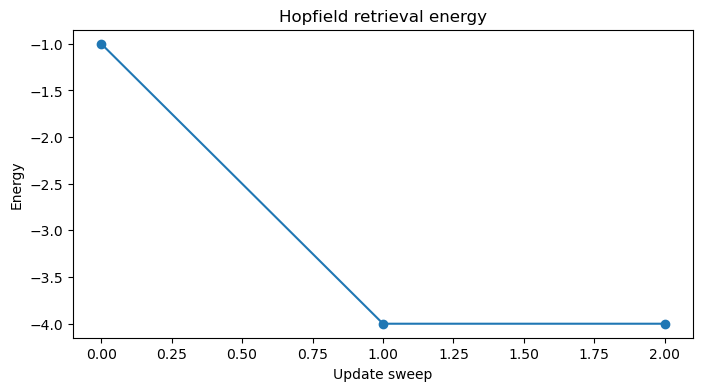

In [9]:
plt.figure(figsize=(8, 4))

plt.plot(
    energies,
    marker="o"
)

plt.xlabel("Update sweep")
plt.ylabel("Energy")
plt.title("Hopfield retrieval energy")
plt.show()

## Ora introduciamo la nostra vera quantità: energy margin

Supponiamo che il ricordo corretto sia s*, e che un concorrente sia s^(c).
Se M_c > 0, allora il target ha energia più bassa.

In [10]:
def energy_margins(
    target_idx,
    patterns,
    W
):

    target = patterns[target_idx]

    E_target = energy(
        target,
        W
    )

    rows = []

    for j, candidate in enumerate(patterns):

        if j == target_idx:
            continue

        E_c = energy(
            candidate,
            W
        )

        margin = (
            E_c - E_target
        )

        rows.append(
            (
                j,
                E_target.item(),
                E_c.item(),
                margin.item()
            )
        )

    return rows

In [11]:
for row in energy_margins(
    0,
    patterns,
    W
):
    print(row)

(1, -6.0, -6.0, 0.0)
(2, -6.0, -6.0, 0.0)
(3, -6.0, -6.0, 0.0)


## Ogni connessione a un errore contribuisce:
### C_ij = -W_ij(c_i*c_j - s ^*_i*s ^*j)

In [12]:
def edge_energy_attribution(
    target,
    competitor,
    W
):

    A = torch.zeros_like(W)

    for i in range(N):

        for j in range(i + 1, N):

            contribution = (
                -W[i, j]
                *
                (
                    competitor[i]
                    * competitor[j]
                    -
                    target[i]
                    * target[j]
                )
            )

            A[i, j] = contribution
            A[j, i] = contribution

    return A

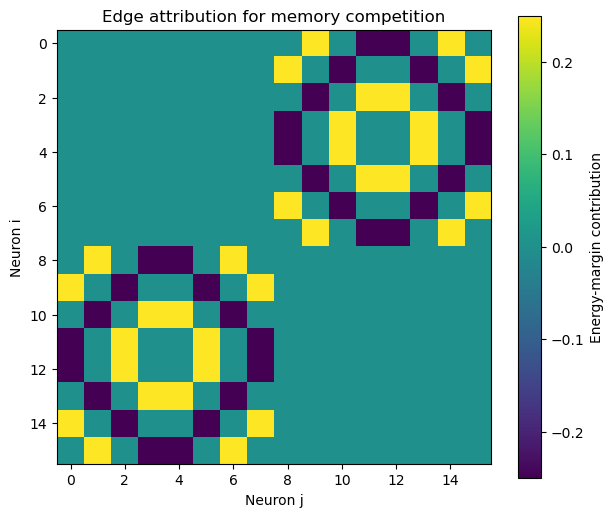

In [13]:
# Esempio
A = edge_energy_attribution(
    patterns[0],
    patterns[1],
    W
)

plt.figure(figsize=(7, 6))

plt.imshow(A)

plt.colorbar(
    label="Energy-margin contribution"
)

plt.xlabel("Neuron j")
plt.ylabel("Neuron i")

plt.title(
    "Edge attribution for memory competition"
)

plt.show()


In [14]:
# Eliminando una connessione W_ij ed eliminandola, come cambia
# I = M(W_ij=0) - M ?
def intervention_effect(
    target,
    competitor,
    W,
    i,
    j
):

    baseline_margin = (
        energy(competitor, W)
        -
        energy(target, W)
    )

    W_do = W.clone()

    W_do[i, j] = 0.0
    W_do[j, i] = 0.0

    intervened_margin = (
        energy(competitor, W_do)
        -
        energy(target, W_do)
    )

    effect = (
        intervened_margin
        -
        baseline_margin
    )

    return effect.item()

In [15]:
causal_map = torch.zeros_like(W)

for i in range(N):

    for j in range(i + 1, N):

        effect = intervention_effect(
            patterns[0],
            patterns[1],
            W,
            i,
            j
        )

        causal_map[i, j] = effect
        causal_map[j, i] = effect

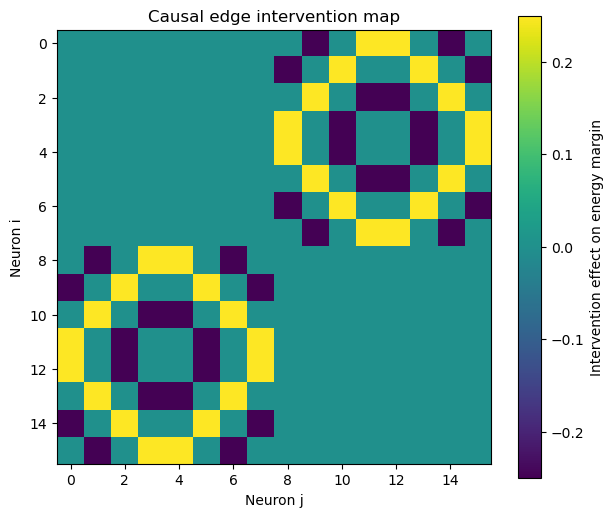

In [16]:
plt.figure(figsize=(7, 6))

plt.imshow(causal_map)

plt.colorbar(
    label="Intervention effect on energy margin"
)

plt.xlabel("Neuron j")
plt.ylabel("Neuron i")

plt.title(
    "Causal edge intervention map"
)

plt.show()

# Ma l'attribuzione predice davvero l'effetto?
### Flatteniamo il triangolo superiore

In [17]:
attrib = []
causal = []

for i in range(N):

    for j in range(i + 1, N):

        attrib.append(
            A[i, j].item()
        )

        causal.append(
            causal_map[i, j].item()
        )

attrib = np.array(attrib)
causal = np.array(causal)

corr = np.corrcoef(
    attrib,
    causal
)[0, 1]

print(
    "Correlation attribution/intervention:",
    corr
)

Correlation attribution/intervention: -1.0


## Corrompendo 4 bit, restano 1820 combinazioni possibili.

In [18]:
def hopfield_retrieve_deterministic(
    initial_state,
    W,
    max_sweeps=20
):
    s = initial_state.clone()

    for _ in range(max_sweeps):

        changed = False

        for i in range(len(s)):

            field = torch.dot(
                W[i],
                s
            )

            new_value = (
                1.0 if field >= 0
                else -1.0
            )

            if new_value != s[i]:
                s[i] = new_value
                changed = True

        if not changed:
            break

    return s

In [19]:
import itertools

def all_corruptions(pattern, n_flips=4):

    corrupted_states = []

    for indices in itertools.combinations(
        range(len(pattern)),
        n_flips
    ):

        x = pattern.clone()

        for i in indices:
            x[i] *= -1

        corrupted_states.append(
            (indices, x)
        )

    return corrupted_states

In [20]:
def retrieval_accuracy(
    target,
    W,
    n_flips=4
):

    corruptions = all_corruptions(
        target,
        n_flips
    )

    correct = 0

    for _, x in corruptions:

        retrieved = (
            hopfield_retrieve_deterministic(
                x,
                W
            )
        )

        if torch.equal(
            retrieved,
            target
        ):
            correct += 1

    return correct / len(corruptions)

In [25]:
target = patterns[0]

baseline_acc = retrieval_accuracy(
    target,
    W,
    n_flips=4
)

print(
    "Baseline retrieval accuracy:",
    baseline_acc
)

Baseline retrieval accuracy: 0.6780219780219781


In [22]:
def behavioral_edge_interventions(
    target,
    W,
    n_flips=4
):

    baseline = retrieval_accuracy(
        target,
        W,
        n_flips
    )

    effects = torch.zeros_like(W)

    for i in range(N):

        for j in range(i + 1, N):

            W_do = W.clone()

            W_do[i, j] = 0.0
            W_do[j, i] = 0.0

            acc_do = retrieval_accuracy(
                target,
                W_do,
                n_flips
            )

            effect = (
                acc_do - baseline
            )

            effects[i, j] = effect
            effects[j, i] = effect

    return baseline, effects

In [23]:
baseline_acc, behavioral_causal_map = (
    behavioral_edge_interventions(
        patterns[0],
        W,
        n_flips=4
    )
)

print(
    "Baseline accuracy:",
    baseline_acc
)

Baseline accuracy: 0.6780219780219781


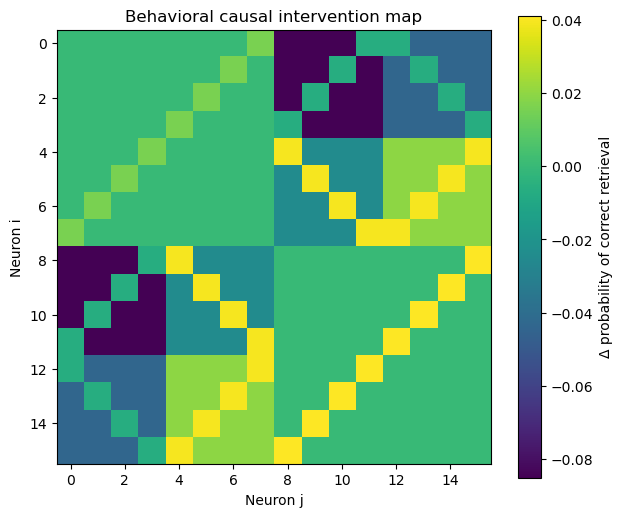

In [24]:
plt.figure(figsize=(7, 6))

plt.imshow(
    behavioral_causal_map
)

plt.colorbar(
    label="Δ probability of correct retrieval"
)

plt.xlabel("Neuron j")
plt.ylabel("Neuron i")

plt.title(
    "Behavioral causal intervention map"
)

plt.show()

# Se f(x | do(W_ij = 0)) = 1 -> quella connessione è causa controfattuale correggibile dell'errore.

In [26]:
def counterfactual_error_map(
    target,
    W,
    n_flips=4
):

    corruptions = all_corruptions(
        target,
        n_flips
    )

    # --------------------------
    # Troviamo solo i fallimenti
    # --------------------------

    failures = []

    for indices, x in corruptions:

        retrieved = (
            hopfield_retrieve_deterministic(
                x,
                W
            )
        )

        if not torch.equal(
            retrieved,
            target
        ):
            failures.append(
                (indices, x)
            )

    print(
        "Numero di errori:",
        len(failures)
    )

    # --------------------------
    # Intervention map
    # --------------------------

    rescue_map = torch.zeros_like(W)

    for i in range(N):

        for j in range(i + 1, N):

            W_do = W.clone()

            W_do[i, j] = 0.0
            W_do[j, i] = 0.0

            rescued = 0

            for _, x in failures:

                retrieved_do = (
                    hopfield_retrieve_deterministic(
                        x,
                        W_do
                    )
                )

                if torch.equal(
                    retrieved_do,
                    target
                ):
                    rescued += 1

            rescue_fraction = (
                rescued / len(failures)
                if len(failures) > 0
                else 0.0
            )

            rescue_map[i, j] = rescue_fraction
            rescue_map[j, i] = rescue_fraction

    return failures, rescue_map

Numero di errori: 586


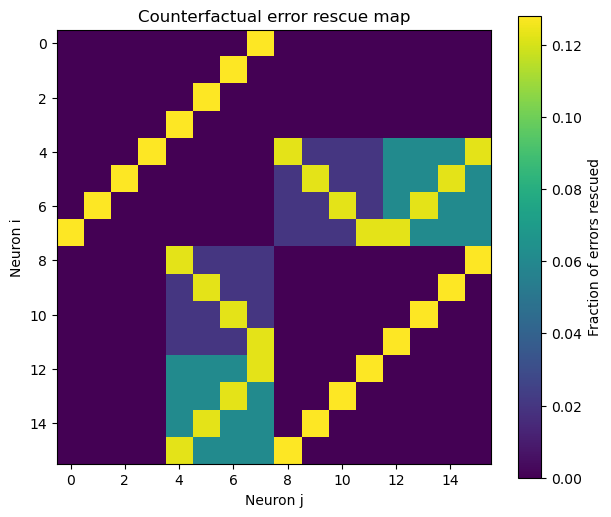

In [27]:
failures, rescue_map = (
    counterfactual_error_map(
        patterns[0],
        W,
        n_flips=4
    )
)

plt.figure(figsize=(7,6))

plt.imshow(rescue_map)

plt.colorbar(
    label="Fraction of errors rescued"
)

plt.xlabel("Neuron j")
plt.ylabel("Neuron i")

plt.title(
    "Counterfactual error rescue map"
)

plt.show()

In [30]:
# Salva dati
torch.save({
    "patterns": patterns,
    "W": W
}, "hopfield_state.pt")